Step 1: Load the data

In [13]:
import pandas as pd
df = pd.read_csv('airline_tweets - airline_tweets.csv')
df.head()

,text,airline_sentiment,airline
0,@VirginAmerica What @dhepburn said.,neutral,Virgin America
1,@VirginAmerica plus you've added commercials t...,positive,Virgin America
2,@VirginAmerica I didn't today... Must mean I n...,neutral,Virgin America
3,@VirginAmerica it's really aggressive to blast...,negative,Virgin America
4,@VirginAmerica and it's a really big bad thing...,negative,Virgin America


In [14]:
df['airline_sentiment'].value_counts()

,count
airline_sentiment,
negative,9178
neutral,3099
positive,2363


Step 2: Set up VADER

In [15]:
!pip install vaderSentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 3.8 MB/s eta 0:00:00


Step 3: Run VADER on the tweets

In [16]:
def get_sentiment(text):
  score = analyzer.polarity_scores(str(text))['compound']
  if score >= 0.05:
    return 'positive'
  elif score <= -0.05:
    return 'negative'
  else:
    return 'neutral'

In [17]:
df['vader_sentiment'] = df['text'].apply(get_sentiment)
df[['text', 'vader_sentiment']].head()

,text,vader_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,neutral
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


Step 4: Count and visualize the results

In [19]:
df['vader_sentiment'].value_counts()

,count
vader_sentiment,
positive,7615
negative,4464
neutral,2561


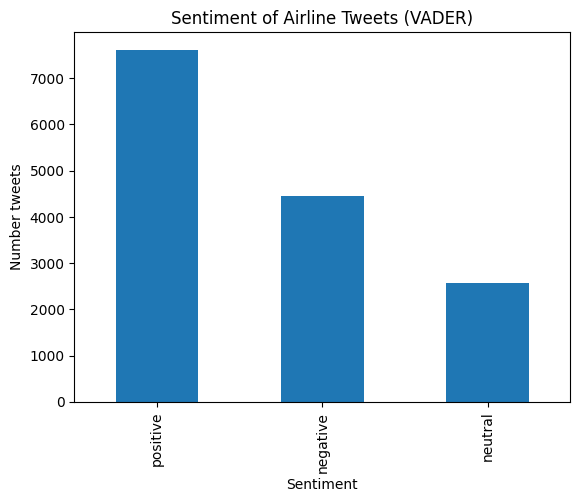

In [20]:
import matplotlib.pyplot as plt
df['vader_sentiment'].value_counts().plot(kind='bar')
plt.title('Sentiment of Airline Tweets (VADER)')
plt.xlabel('Sentiment')
plt.ylabel('Number tweets')
plt.show()

Step 5: Compare with the humans, and hunt for sarcasm

In [21]:
df[['text', 'airline_sentiment', 'vader_sentiment']].head(20)

,text,airline_sentiment,vader_sentiment
0,@VirginAmerica What @dhepburn said.,neutral,neutral
1,@VirginAmerica plus you've added commercials t...,positive,neutral
2,@VirginAmerica I didn't today... Must mean I n...,neutral,neutral
3,@VirginAmerica it's really aggressive to blast...,negative,negative
4,@VirginAmerica and it's a really big bad thing...,negative,negative
5,@VirginAmerica seriously would pay $30 a fligh...,negative,negative
6,"@VirginAmerica yes, nearly every time I fly VX...",positive,positive
7,@VirginAmerica Really missed a prime opportuni...,neutral,positive
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive,positive
9,"@VirginAmerica it was amazing, and arrived an ...",positive,positive


In [22]:
# tweets where VADER and the humans disagree
mismatch = df[df['vader_sentiment'] != df['airline_sentiment']]
mismatch[['text', 'airline_sentiment', 'vader_sentiment']].head(10)

,text,airline_sentiment,vader_sentiment
1,@VirginAmerica plus you've added commercials t...,positive,neutral
7,@VirginAmerica Really missed a prime opportuni...,neutral,positive
10,@VirginAmerica did you know that suicide is th...,neutral,negative
16,@VirginAmerica So excited for my first cross c...,positive,negative
17,@VirginAmerica I flew from NYC to SFO last we...,negative,positive
20,@VirginAmerica why are your first fares in May...,negative,neutral
23,@VirginAmerica will you be making BOS&gt;LAS n...,neutral,negative
24,@VirginAmerica you guys messed up my seating.....,negative,positive
27,@VirginAmerica do you miss me? Don't worry we'...,neutral,positive
28,@VirginAmerica amazing to me that we can't get...,negative,positive
